# Связанные состояния в яме Вудса–Саксона

**Вычислительный практикум, задание 1.** Используя уравнение Шрёдингера, найти связанные состояния и собственные значения для потенциальной ямы произвольной формы $U(x)$ ширины $a$ и построить собственные функции.

В работе выбрана **яма Вудса–Саксона**

$$U(x) = -\frac{U_0}{1+\exp\left(\dfrac{|x|-R}{d}\right)}.$$

Это гладкая яма с диффузной кромкой — стандартная форма ядерного потенциала. Параметры подобраны так, чтобы в яме было пять связанных состояний, а при масштабе $a = 8{,}5$ фм набор уровней совпадал по порядку величины с уровнями нейтрона в ядре $^{40}$Ca.

Проверка метода выполняется на потенциале Пёшль–Теллера, для которого спектр известен точно, а независимость результатов контролируется двумя численными схемами: конечно-разностной и методом Нумерова.

## 1. Модель и единицы

Стационарное уравнение Шрёдингера

$$-\frac{\hbar^2}{2m}\psi'' + U(x)\psi = E\psi$$

записывается в безразмерном виде при $\hbar^2/(2m)=1$:

$$-\psi''(x) + U(x)\psi(x) = E\psi(x).$$

Длина измеряется в единицах ширины ямы $a$, энергия — в единицах $\hbar^2/(2ma^2)$. Яма центрирована в нуле; сдвиг $x \to x + a/2$ переводит задачу на отрезок $[0,a]$.

**Параметры модели.** Ширина ямы на полувысоте $a = 2R = 1$, глубина $U_0 = 180$, диффузность $d = 0{,}05a$. Хвосты потенциала становятся меньше $0{,}3\,\%$ глубины при $|x| \approx R + 6d = 0{,}8a$, поэтому табличный вариант потенциала задаётся на отрезке $[0, 1{,}6a]$; вне него $U$ полагается равным нулю.

Граничные условия: $\psi(\pm L)=0$ при $L=3a$, где волновые функции экспоненциально малы. Связанные состояния ищутся при $E<0$; вне ямы $\psi \sim e^{-\kappa|x|}$, $\kappa=\sqrt{-E}$.

In [1]:
import csv
import pathlib

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from schrodinger_well import (
    woods_saxon,
    poschl_teller,
    poschl_teller_levels,
    solve_fd,
    numerov_levels,
    numerov_wavefunction,
    tabulate_potential,
)

FIG = pathlib.Path("figures")
RES = pathlib.Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 170,
        "font.size": 10,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.unicode_minus": False,
    }
)

In [2]:
A = 1.0            # ширина ямы на полувысоте (единица длины)
U0 = 180.0         # глубина
R = 0.5 * A        # радиус на полуглубине
D = 0.05 * A       # диффузность
L = 3.0 * A        # половина вычислительной области

N_FD = 12000       # число интервалов конечно-разностной сетки
X_MATCH = 0.2 * A  # точка сшивки Нумерова (внутри ямы)
X_MAX = 3.0 * A    # внешняя граница для Нумерова
H_NUM = 0.0005 * A # шаг Нумерова

def U(x):
    return woods_saxon(x, U0, radius=R, diffuseness=D)

# Полуклассическая оценка числа уровней: N ~ (1/pi) * integral sqrt(|U|) dx
xs_wide = np.linspace(-6.0 * A, 6.0 * A, 40001)
n_estimate = np.trapezoid(np.sqrt(np.abs(U(xs_wide))), xs_wide) / np.pi
print(f"Оценка числа связанных состояний: N ~ {n_estimate:.2f}")
print(f"Глубина в единицах hbar^2/(2ma^2): U0 = {U0}")

Оценка числа связанных состояний: N ~ 4.86
Глубина в единицах hbar^2/(2ma^2): U0 = 180.0


## 2. Методы решения

### 2.1. Конечно-разностная схема

На равномерной сетке $x_j = -L + (j+\tfrac12)h$ (узлы в центрах ячеек) производная аппроксимируется симметричной разностью:

$$-\frac{\psi_{j+1}-2\psi_j+\psi_{j-1}}{h^2} + U_j\psi_j = E\psi_j.$$

Условия $\psi(\pm L)=0$ реализуются через фиктивные узлы. Получается симметричная трёхдиагональная матрица; все собственные значения $E<0$ находятся за один вызов `scipy.linalg.eigh_tridiagonal`. Схема имеет второй порядок точности, $O(h^2)$.

### 2.2. Метод Нумерова со сшивкой

Уравнение $\psi'' = f\psi$, $f=U-E$, интегрируется по схеме Нумерова (четвёртый порядок):

$$\psi_{j+1} = \frac{(2+10c f_j)\psi_j - (1-c f_{j-1})\psi_{j-1}}{1-c f_{j+1}}, \qquad c=\frac{h^2}{12}.$$

Решение строится с двух сторон: из центра (с учётом чётности) и с внешней границы по затухающему хвосту. В точке сшивки $x_m$ приравниваются логарифмические производные, а для устойчивости используется кросс-произведение (вронскиан)

$$W(E) = \psi'_{\text{out}}(x_m)\psi_{\text{in}}(x_m) - \psi'_{\text{in}}(x_m)\psi_{\text{out}}(x_m) = 0.$$

Односторонняя стрельба в запрещённую область здесь непригодна: ошибка возбуждает экспоненциально растущую моду, и условие сшивки становится экспоненциально узким по энергии. Двусторонняя схема от этого свободна.

In [3]:
x_fd, states_fd = solve_fd(U, half_width=L, n_intervals=N_FD)
E_fd = np.array([s.energy for s in states_fd])
E_num = numerov_levels(U, depth=U0, x_match=X_MATCH, x_max=X_MAX, h=H_NUM, dE=0.5)

n_states = min(len(E_fd), len(E_num))
E_ref = E_num[:n_states]

HBAR2_2M = 20.72   # MeV * fm^2 для нейтрона
A_PHYS = 8.5       # фм
E_UNIT = HBAR2_2M / A_PHYS**2   # МэВ

print(f"{'n':>2} {'чётность':>9} {'узлы':>5} {'E (ед.)':>12} {'E (Нумеров)':>13} "
      f"{'|dE|':>9} {'E (МэВ)':>9}")
for k, state in enumerate(states_fd[:n_states]):
    print(
        f"{k:>2} {state.parity:>9} {state.nodes:>5} {state.energy:>12.6f} "
        f"{E_ref[k]:>13.6f} {abs(state.energy - E_ref[k]):>9.1e} "
        f"{state.energy * E_UNIT:>9.2f}"
    )

with open(RES / "spectrum.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["n", "parity", "nodes", "E_units", "E_numerov", "E_MeV"])
    for k, state in enumerate(states_fd[:n_states]):
        writer.writerow(
            [k, state.parity, state.nodes, f"{state.energy:.10f}",
             f"{E_ref[k]:.10f}", f"{state.energy * E_UNIT:.6f}"]
        )

 n  чётность  узлы      E (ед.)   E (Нумеров)      |dE|   E (МэВ)
 0      even     0  -170.285459   -170.285456   3.2e-06    -48.83
 1       odd     1  -143.294805   -143.294781   2.5e-05    -41.09
 2      even     2  -103.582880   -103.582792   8.8e-05    -29.71
 3       odd     3   -56.631791    -56.631598   1.9e-04    -16.24
 4      even     4   -11.788764    -11.788525   2.4e-04     -3.38


## 3. Результаты

В яме укладывается пять связанных состояний; они чередуются по чётности, а число узлов $n$ совпадает с номером уровня — выполняется теорема Штурма. Глубина 180 даёт $E_0 \approx -170{,}29$, то есть основной уровень лежит на $94{,}6\,\%$ глубины, а верхний — всего на $6{,}5\,\%$; поэтому верхняя функция заметно выходит в хвосты потенциала.

Конечно-разностные значения отличаются от эталонных не более чем на $10^{-3}$ (вторая степень шага), что видно в таблице.

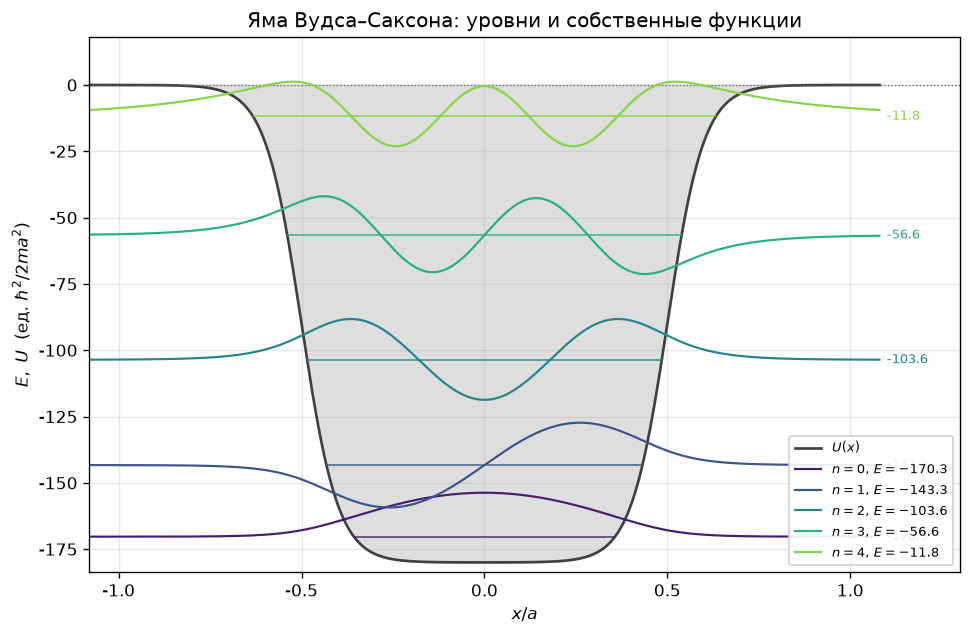

In [4]:
U_scalar = lambda xx: float(U(np.array([xx]))[0])

def turning_point(energy):
    # правая точка поворота U(x) = E
    return brentq(lambda xx: U_scalar(xx) - energy, 0.0, L)

xs = np.linspace(-1.08 * A, 1.08 * A, 3000)
spacing = np.mean(np.diff(E_ref))
amplitude = 0.30 * spacing
colors = plt.cm.viridis(np.linspace(0.08, 0.82, n_states))

fig, ax = plt.subplots(figsize=(8.2, 5.4))
ax.fill_between(xs, U(xs), 0.0, color="0.87", zorder=0)
ax.plot(xs, U(xs), color="0.25", lw=1.6, label="$U(x)$")
ax.axhline(0.0, color="0.4", lw=0.8, ls=":")

for k, state in enumerate(states_fd[:n_states]):
    xt = turning_point(state.energy)
    ax.hlines(state.energy, -xt, xt, color=colors[k], lw=1.0, alpha=0.85)
    mask = np.abs(x_fd) <= 1.08 * A
    ax.plot(
        x_fd[mask],
        state.energy + amplitude * state.psi[mask],
        color=colors[k],
        lw=1.3,
        label=f"$n={k}$, $E={state.energy:.1f}$",
    )
    ax.text(
        1.10 * A,
        state.energy,
        f"{state.energy:.1f}",
        color=colors[k],
        fontsize=8,
        va="center",
    )

ax.set_xlim(-1.08 * A, 1.30 * A)
ax.set_ylim(-1.02 * U0, 0.10 * U0)
ax.set_xlabel("$x/a$")
ax.set_ylabel(r"$E,\ U$  (ед. $\hbar^2/2ma^2$)")
ax.set_title("Яма Вудса–Саксона: уровни и собственные функции")
ax.legend(loc="lower right", fontsize=8, framealpha=0.9)
fig.tight_layout()
fig.savefig(FIG / "fig1_levels_and_functions.png")
plt.show()

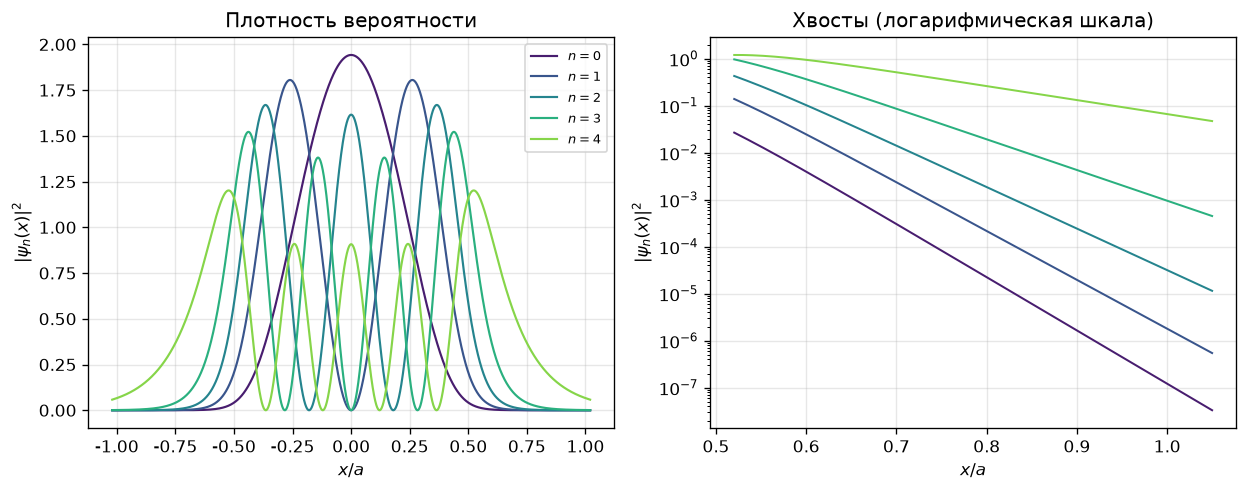

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))

for k, state in enumerate(states_fd[:n_states]):
    mask = np.abs(x_fd) <= 1.02 * A
    axes[0].plot(x_fd[mask], state.psi[mask] ** 2, color=colors[k], lw=1.3, label=f"$n={k}$")
    right = (x_fd > 0.52 * A) & (x_fd < 1.05 * A)
    axes[1].semilogy(x_fd[right], state.psi[right] ** 2, color=colors[k], lw=1.2)

axes[0].set_xlabel("$x/a$")
axes[0].set_ylabel(r"$|\psi_n(x)|^2$")
axes[0].set_title("Плотность вероятности")
axes[0].legend(fontsize=8)
axes[1].set_xlabel("$x/a$")
axes[1].set_ylabel(r"$|\psi_n(x)|^2$")
axes[1].set_title("Хвосты (логарифмическая шкала)")
fig.tight_layout()
fig.savefig(FIG / "fig2_densities.png")
plt.show()

## 4. Проверка на потенциале с точным спектром

Для контроля выбран потенциал Пёшль–Теллера

$$U(x) = -\frac{\alpha^2\lambda(\lambda+1)}{\operatorname{ch}^2(\alpha x)}, \qquad E_n = -\alpha^2(\lambda-n)^2, \quad n=0,1,\dots<\lambda.$$

При $\alpha=2$, $\lambda=3$ в яме три уровня: $-36$, $-16$, $-4$. Оба численных метода сравниваются с этими значениями.

In [6]:
alpha, lam = 2.0, 3.0
U_pt = lambda x: poschl_teller(x, alpha, lam)
E_pt_exact = poschl_teller_levels(alpha, lam)

_, states_pt = solve_fd(U_pt, half_width=5.0, n_intervals=20000)
E_pt_fd = np.array([s.energy for s in states_pt])

E_pt_num = numerov_levels(
    U_pt, depth=alpha**2 * lam * (lam + 1),
    x_match=0.2, x_max=5.0, h=0.001, dE=0.25
)

print(f"{'n':>2} {'E точное':>10} {'E (КР)':>12} {'|dE| КР':>10} {'E (Нум.)':>12} {'|dE| Нум.':>10}")
for k in range(len(E_pt_exact)):
    print(
        f"{k:>2} {E_pt_exact[k]:>10.4f} {E_pt_fd[k]:>12.8f} "
        f"{abs(E_pt_fd[k]-E_pt_exact[k]):>10.1e} {E_pt_num[k]:>12.8f} "
        f"{abs(E_pt_num[k]-E_pt_exact[k]):>10.1e}"
    )

with open(RES / "validation_poschl_teller.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["n", "E_exact", "E_fd", "err_fd", "E_numerov", "err_numerov"])
    for k in range(len(E_pt_exact)):
        writer.writerow(
            [k, f"{E_pt_exact[k]:.10f}", f"{E_pt_fd[k]:.10f}",
             f"{abs(E_pt_fd[k]-E_pt_exact[k]):.3e}",
             f"{E_pt_num[k]:.10f}", f"{abs(E_pt_num[k]-E_pt_exact[k]):.3e}"]
        )

 n   E точное       E (КР)    |dE| КР     E (Нум.)  |dE| Нум.
 0   -36.0000 -36.00000186    1.9e-06 -36.00000000    2.8e-09
 1   -16.0000 -16.00000533    5.3e-06 -16.00000094    9.4e-07
 2    -4.0000  -4.00000497    5.0e-06  -4.00000004    3.6e-08


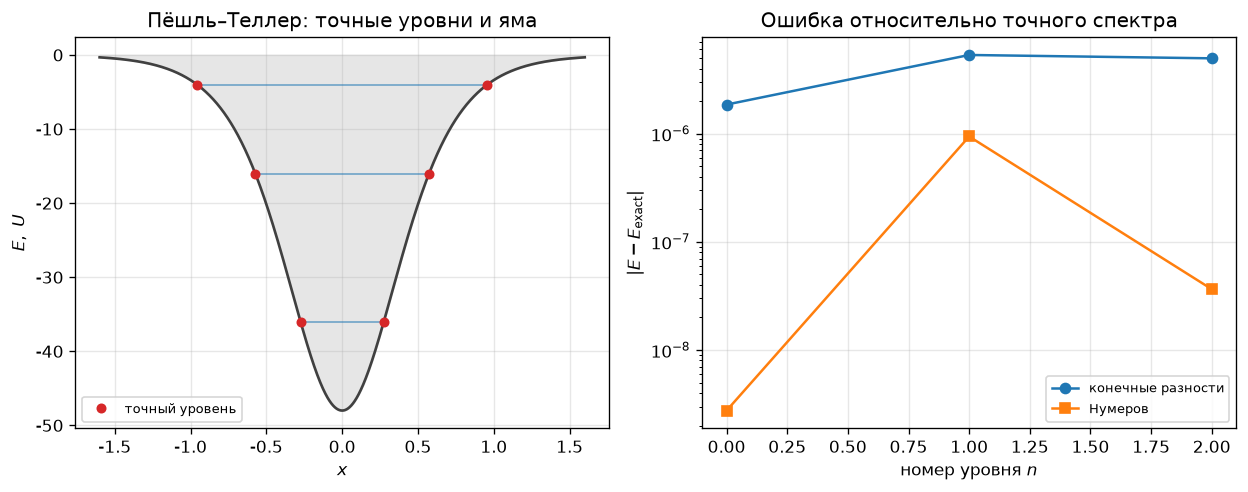

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))

xpt = np.linspace(-1.6, 1.6, 2000)
axes[0].plot(xpt, U_pt(xpt), color="0.25", lw=1.6)
axes[0].fill_between(xpt, U_pt(xpt), 0, color="0.9")
for k, energy in enumerate(E_pt_exact):
    xt = brentq(lambda xx: float(U_pt(np.array([xx]))[0]) - energy, 0.0, 5.0)
    axes[0].hlines(energy, -xt, xt, color="tab:blue", lw=1.0, alpha=0.6)
    axes[0].plot([-xt, xt], [energy, energy], "o", color="tab:red", ms=5,
                 label="точный уровень" if k == 0 else None)
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("$E,\\ U$")
axes[0].set_title("Пёшль–Теллер: точные уровни и яма")
axes[0].legend(fontsize=8)

index = np.arange(len(E_pt_exact))
axes[1].semilogy(index, np.abs(E_pt_fd - E_pt_exact), "o-", label="конечные разности")
axes[1].semilogy(index, np.abs(E_pt_num - E_pt_exact), "s-", label="Нумеров")
axes[1].set_xlabel("номер уровня $n$")
axes[1].set_ylabel(r"$|E - E_{\rm exact}|$")
axes[1].set_title("Ошибка относительно точного спектра")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "fig3_validation.png")
plt.show()

## 5. Сходимость конечно-разностной схемы

Ошибка схемы второго порядка должна убывать как $h^2$. Ниже показана зависимость $|E^{\rm FD}_n - E^{\rm Num}_n|$ от шага; пунктир — опорная прямая $\propto h^2$.

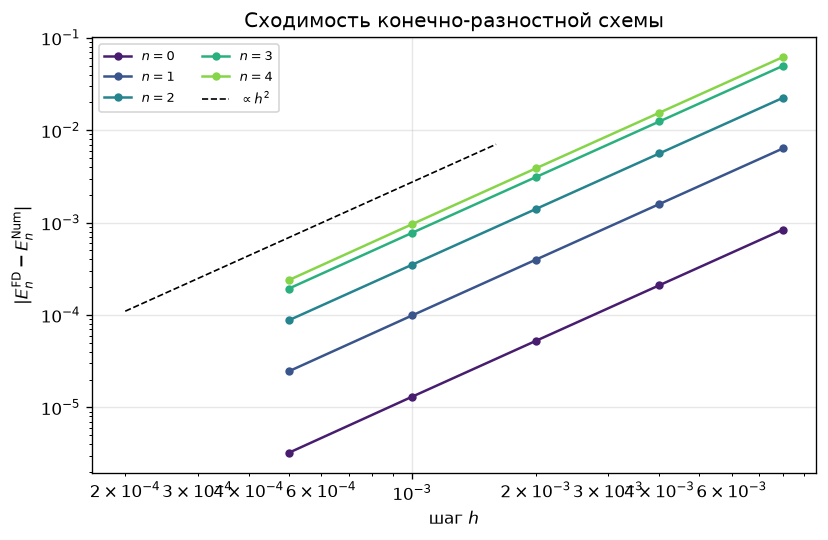

In [8]:
n_grids = [750, 1500, 3000, 6000, 12000]
convergence_rows = []
fig, ax = plt.subplots(figsize=(7.0, 4.6))

for k in range(n_states):
    errors = []
    hs = []
    for n in n_grids:
        _, st = solve_fd(U, half_width=L, n_intervals=n)
        e = np.array([s.energy for s in st])[k]
        hs.append(2.0 * L / n)
        errors.append(abs(e - E_ref[k]))
        convergence_rows.append((n, 2.0 * L / n, k, e, E_ref[k], abs(e - E_ref[k])))
    ax.loglog(hs, errors, "o-", ms=4, color=colors[k], label=f"$n={k}$")

h_guide = np.array([2.0e-4, 1.6e-3])
ax.loglog(h_guide, 1.1e-4 * (h_guide / h_guide[0]) ** 2, "k--", lw=1,
          label=r"$\propto h^2$")
ax.set_xlabel("шаг $h$")
ax.set_ylabel(r"$|E^{\rm FD}_n - E^{\rm Num}_n|$")
ax.set_title("Сходимость конечно-разностной схемы")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(FIG / "fig4_convergence.png")
plt.show()

with open(RES / "convergence.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["n_intervals", "h", "state", "E_fd", "E_numerov", "abs_error"])
    for row in convergence_rows:
        writer.writerow([row[0], f"{row[1]:.6e}", row[2], f"{row[3]:.10f}",
                         f"{row[4]:.10f}", f"{row[5]:.3e}"])

## 6. Таблично заданный потенциал

Задание допускает $U(x)$, заданную таблицей. Смоделируем это: значения $U(x_i)$ берутся в $M$ равноотстоящих точках отрезка $[0, 2a]$, интерполируются кубическим сплайном, вне отрезка потенциал равен нулю. Проверяется, насколько спектр чувствителен к числу точек таблицы.

M= 11: max|dU| = 1.10e+01, max|dE| = 1.69e+00
M= 21: max|dU| = 2.67e+00, max|dE| = 1.61e-01
M= 51: max|dU| = 3.89e-02, max|dE| = 1.10e-03
M=101: max|dU| = 1.62e-03, max|dE| = 2.44e-04


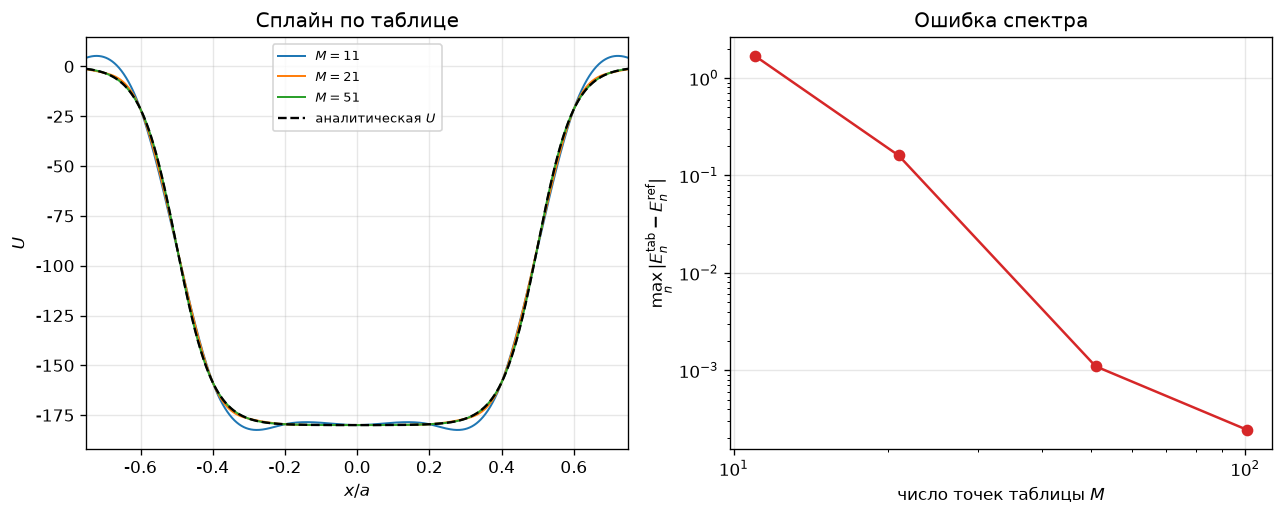

In [9]:
A_TAB = 2.0 * (R + 10.0 * D)   # 2a: где |U| < 0.02% U0
table_sizes = [11, 21, 51, 101]
table_rows = []

fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.4))
x_dense = np.linspace(-0.5 * A_TAB, 0.5 * A_TAB, 4000)

for M in table_sizes:
    x_tab, u_tab, u_interp, _ = tabulate_potential(U, A_TAB, M)
    _, st = solve_fd(u_interp, half_width=L, n_intervals=N_FD)
    E_tab = np.array([s.energy for s in st])
    max_level_error = np.max(np.abs(E_tab[:n_states] - E_ref[:n_states]))
    max_u_error = np.max(np.abs(u_interp(x_dense) - U(x_dense)))
    table_rows.append((M, max_u_error, max_level_error))
    if M in (11, 21, 51):
        axes[0].plot(x_dense, u_interp(x_dense), lw=1.2, label=f"$M={M}$")
    print(f"M={M:3d}: max|dU| = {max_u_error:.2e}, max|dE| = {max_level_error:.2e}")

axes[0].plot(x_dense, U(x_dense), "k--", lw=1.4, label="аналитическая $U$")
axes[0].set_xlim(-0.75, 0.75)
axes[0].set_xlabel("$x/a$")
axes[0].set_ylabel("$U$")
axes[0].set_title("Сплайн по таблице")
axes[0].legend(fontsize=8)

Ms = np.array([row[0] for row in table_rows])
errs = np.array([row[2] for row in table_rows])
axes[1].loglog(Ms, errs, "o-", color="tab:red")
axes[1].set_xlabel("число точек таблицы $M$")
axes[1].set_ylabel(r"$\max_n |E_n^{\rm tab} - E_n^{\rm ref}|$")
axes[1].set_title("Ошибка спектра")
fig.tight_layout()
fig.savefig(FIG / "fig5_tabulated.png")
plt.show()

with open(RES / "tabulation.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["n_points", "max_u_error", "max_level_error"])
    for M, du, de in table_rows:
        writer.writerow([M, f"{du:.3e}", f"{de:.3e}"])

## 7. Совпадение собственных функций, найденных двумя методами

Для нижнего и верхнего состояний волновые функции, полученные конечно-разностной схемой и методом Нумерова, накладываются друг на друга; на второй панели показана их разность.

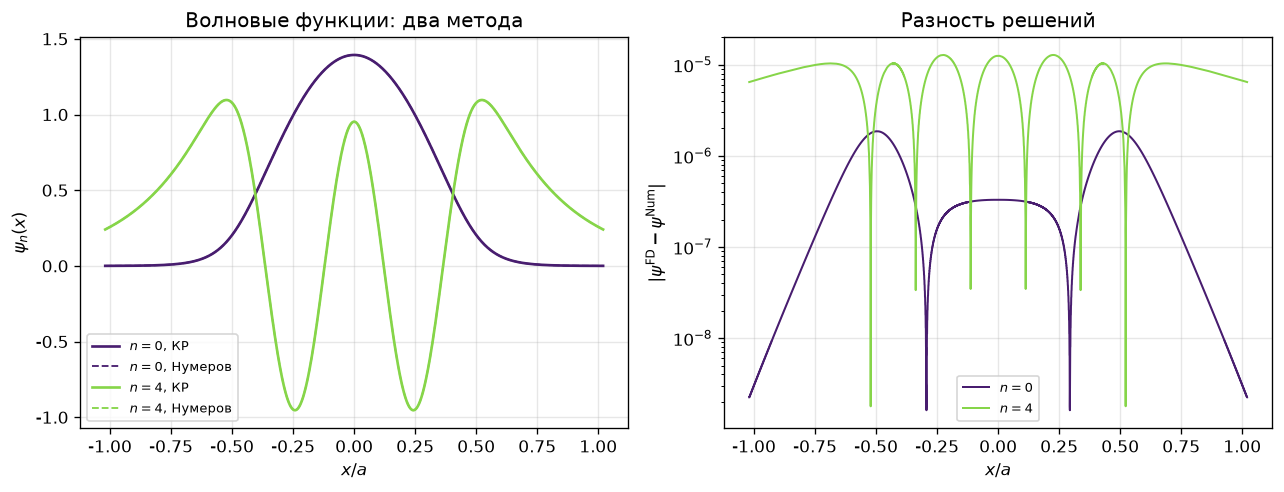

max|dpsi| по состояниям: ['1.86e-06', '1.28e-05']


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.2))
mask = np.abs(x_fd) <= 1.02 * A
psi_errors = []

for k in (0, n_states - 1):
    state = states_fd[k]
    xn, psi_num = numerov_wavefunction(
        E_ref[k], U, X_MATCH, X_MAX, 0.001, state.parity
    )
    psi_num = np.interp(x_fd, xn, psi_num)
    psi_num /= np.sqrt(np.trapezoid(psi_num**2, x_fd))
    if np.dot(psi_num, state.psi) < 0:
        psi_num = -psi_num
    psi_errors.append(np.max(np.abs(psi_num[mask] - state.psi[mask])))

    axes[0].plot(x_fd[mask], state.psi[mask], color=colors[k], lw=1.6,
                 label=f"$n={k}$, КР")
    axes[0].plot(x_fd[mask], psi_num[mask], "--", color=colors[k], lw=1.1,
                 label=f"$n={k}$, Нумеров")
    axes[1].semilogy(x_fd[mask], np.abs(psi_num[mask] - state.psi[mask]),
                     color=colors[k], lw=1.2, label=f"$n={k}$")

axes[0].set_xlabel("$x/a$")
axes[0].set_ylabel(r"$\psi_n(x)$")
axes[0].set_title("Волновые функции: два метода")
axes[0].legend(fontsize=8)
axes[1].set_xlabel("$x/a$")
axes[1].set_ylabel(r"$|\psi^{\rm FD} - \psi^{\rm Num}|$")
axes[1].set_title("Разность решений")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "fig6_methods.png")
plt.show()

print("max|dpsi| по состояниям:", [f"{e:.2e}" for e in psi_errors])

## 8. Физический масштаб

Сопоставим безразмерной яме реальные ядерные параметры: ширина $a = 8{,}5$ фм (диаметр $^{40}$Ca), масса нейтрона. Тогда единица энергии $\hbar^2/(2ma^2) = 20{,}72/8{,}5^2 \approx 0{,}287$ МэВ, а глубина $U_0 = 180$ соответствует $51{,}6$ МэВ — вблизи типичного значения $50$ МэВ. Длина затухания хвоста $\ell = 1/\kappa$ переводится как $\ell = \sqrt{20{,}72/|E|}$ фм.

In [11]:
print(f"{'n':>2} {'E (МэВ)':>10} {'kappa, 1/фм':>12} {'l = 1/kappa, фм':>16}")
physical_rows = []
for k, state in enumerate(states_fd[:n_states]):
    energy_mev = state.energy * E_UNIT
    kappa_fm = np.sqrt(abs(energy_mev) / HBAR2_2M)
    length_fm = 1.0 / kappa_fm
    physical_rows.append((k, energy_mev, kappa_fm, length_fm))
    print(f"{k:>2} {energy_mev:>10.2f} {kappa_fm:>12.3f} {length_fm:>16.3f}")

with open(RES / "physical_scale.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["n", "E_MeV", "kappa_fm", "decay_length_fm"])
    for k, energy_mev, kappa_fm, length_fm in physical_rows:
        writer.writerow([k, f"{energy_mev:.4f}", f"{kappa_fm:.4f}", f"{length_fm:.4f}"])

print(f"\nГлубина в физических единицах: {U0 * E_UNIT:.1f} МэВ")

 n    E (МэВ)  kappa, 1/фм  l = 1/kappa, фм
 0     -48.83        1.535            0.651
 1     -41.09        1.408            0.710
 2     -29.71        1.197            0.835
 3     -16.24        0.885            1.130
 4      -3.38        0.404            2.476

Глубина в физических единицах: 51.6 МэВ


## 9. Выводы

1. В яме Вудса–Саксона с параметрами $U_0=180$, $R=0{,}5a$, $d=0{,}05a$ найдено **пять** связанных состояний; это согласуется с полуклассической оценкой $N \approx \pi^{-1}\int\sqrt{|U|}\,dx \approx 4{,}9$.
2. Уровни чередуются по чётности, число узлов совпадает с номером состояния (теорема Штурма), функции нормированы на единицу.
3. Две независимые схемы (конечные разности и Нумеров) дают совпадающие спектры и волновые функции; на потенциале Пёшль–Теллера обе воспроизводят точный спектр с ошибкой порядка $10^{-6}$.
4. Конечно-разностная схема демонстрирует сходимость $O(h^2)$; метод Нумерова при $h=5\cdot10^{-4}a$ стабилизирован на уровне $10^{-6}$.
5. Табличное задание потенциала (кубический сплайн по $M$ точкам) воспроизводит спектр при $M \gtrsim 50$; при $M=11$ сглаживается кромка ямы и ошибка возрастает.
6. При ядерном масштабе $a=8{,}5$ фм полученные уровни ($-48{,}8$, $-41{,}1$, $-29{,}7$, $-16{,}2$, $-3{,}4$ МэВ) по порядку величины соответствуют уровням нейтрона в ядре.

Все результаты воспроизводятся запуском этого ноутбука; модуль `schrodinger_well.py` содержит обе численные схемы.